In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# Load the UCI Arrhythmia dataset

data_path = "../data/arrhythmia.data"

df = pd.read_csv(data_path, header=None)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 452
Number of columns: 280


In [3]:
# Display the first 5 rows of the dataset

df.head()

,0,1,2,3,4,5,6,7,8,9,...,270,271,272,273,274,275,276,277,278,279
0,75,0,190,80,91,193,371,174,121,-16,...,0.0,9.0,-0.9,0.0,0.0,0.9,2.9,23.3,49.4,8
1,56,1,165,64,81,174,401,149,39,25,...,0.0,8.5,0.0,0.0,0.0,0.2,2.1,20.4,38.8,6
2,54,0,172,95,138,163,386,185,102,96,...,0.0,9.5,-2.4,0.0,0.0,0.3,3.4,12.3,49.0,10
3,55,0,175,94,100,202,380,179,143,28,...,0.0,12.2,-2.2,0.0,0.0,0.4,2.6,34.6,61.6,1
4,75,0,190,80,88,181,360,177,103,-16,...,0.0,13.1,-3.6,0.0,0.0,-0.1,3.9,25.4,62.8,7


In [4]:
# Check missing values in the dataset

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())
print("Columns containing missing values:", (missing_values > 0).sum())

Total missing values: 0
Columns containing missing values: 0


In [5]:
# Check for '?' values in the dataset

question_marks = (df == '?').sum().sum()

print("Total '?' values in dataset:", question_marks)

Total '?' values in dataset: 408


In [6]:
# Convert '?' into proper missing values

df = df.replace('?', np.nan)

# Check again
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 408


In [7]:
# Find columns that contain missing values

missing_by_column = df.isnull().sum()

print("Columns with missing values:")
print(missing_by_column[missing_by_column > 0])

Columns with missing values:
10      8
11     22
12      1
13    376
14      1
dtype: int64


In [8]:
# Remove Feature 14 from the paper
# In Python indexing, Feature 14 is column 13

df = df.drop(columns=[13])

print("Dataset shape after removing Feature 14:", df.shape)

Dataset shape after removing Feature 14: (452, 279)


In [9]:
# Convert all columns to numeric values

df = df.apply(pd.to_numeric, errors='coerce')

print("Data converted to numeric format.")
print("Remaining missing values:", df.isnull().sum().sum())

Data converted to numeric format.
Remaining missing values: 32


In [10]:
# Check the last column (target/class)

print("Last column number:", df.columns[-1])
print("Unique target classes:")
print(sorted(df.iloc[:, -1].dropna().unique()))

Last column number: 279
Unique target classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(14), np.int64(15), np.int64(16)]


In [11]:
# Separate features (X) and target (y)

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Features (X) shape: (452, 278)
Target (y) shape: (452,)
Missing values in X: 32
Missing values in y: 0


In [12]:
from sklearn.impute import SimpleImputer

# Create median imputer
imputer = SimpleImputer(strategy="median")

# Fill missing values in X
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("Missing values before imputation:", X.isnull().sum().sum())
print("Missing values after imputation:", X_imputed.isnull().sum().sum())
print("Final X shape:", X_imputed.shape)

Missing values before imputation: 32
Missing values after imputation: 0
Final X shape: (452, 278)


In [13]:
from sklearn.model_selection import train_test_split

# Split data: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (316, 278)
Testing data: (136, 278)
Training target: (316,)
Testing target: (136,)


In [14]:
from sklearn.tree import DecisionTreeClassifier

# Create CART Decision Tree
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train CART
cart_model.fit(X_train, y_train)

print("CART model trained successfully!")

CART model trained successfully!


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Make predictions on the test data
y_pred_cart = cart_model.predict(X_test)

# Calculate evaluation metrics
cart_accuracy = accuracy_score(y_test, y_pred_cart)
cart_precision = precision_score(y_test, y_pred_cart, average='weighted', zero_division=0)
cart_recall = recall_score(y_test, y_pred_cart, average='weighted', zero_division=0)
cart_f1 = f1_score(y_test, y_pred_cart, average='weighted', zero_division=0)

print("CART RESULTS")
print("--------------------")
print("Accuracy :", round(cart_accuracy * 100, 2), "%")
print("Precision:", round(cart_precision, 4))
print("Recall   :", round(cart_recall, 4))
print("F1-Score :", round(cart_f1, 4))

CART RESULTS
--------------------
Accuracy : 69.12 %
Precision: 0.6746
Recall   : 0.6912
F1-Score : 0.678


<Figure size 1000x800 with 0 Axes>

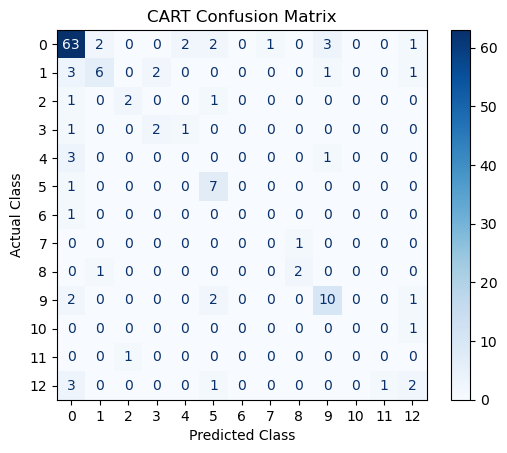

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_cart)

# Display confusion matrix
plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")

plt.title("CART Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

<Figure size 1000x800 with 0 Axes>

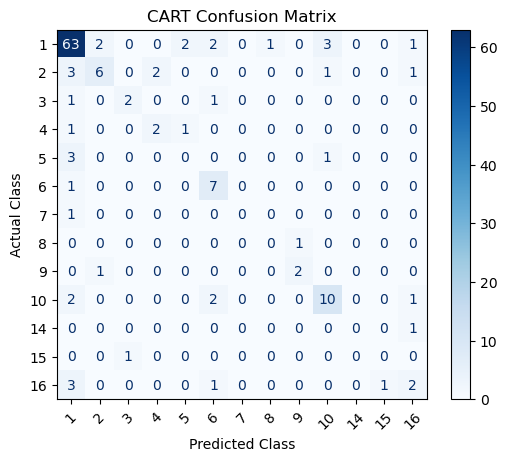

In [17]:
# Correct confusion matrix with actual class labels

class_labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    y_pred_cart,
    labels=class_labels
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(cmap="Blues", values_format="d")

plt.title("CART Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.show()

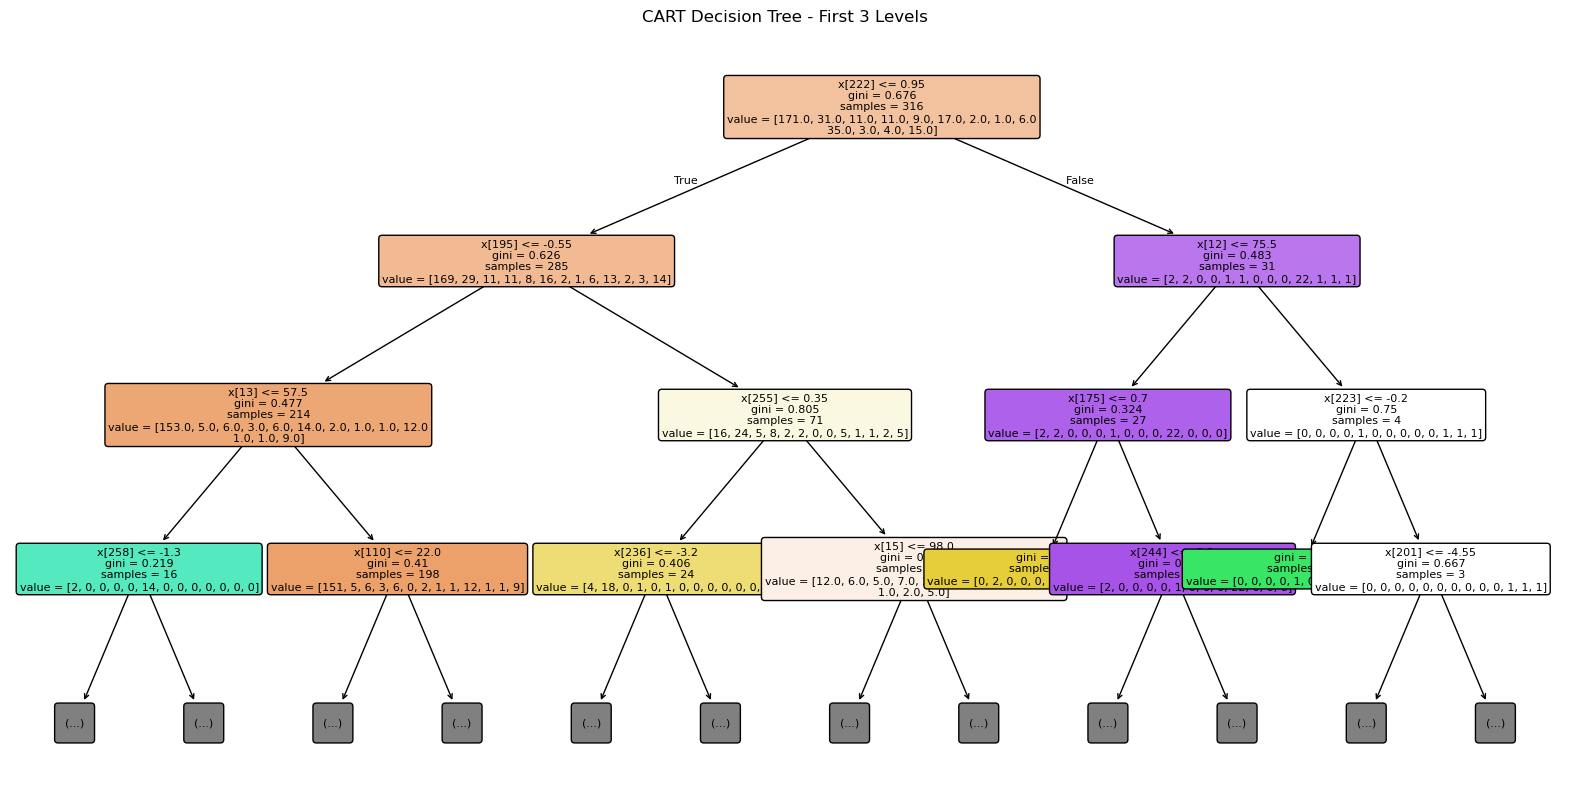

In [18]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree - First 3 Levels")
plt.show()

In [19]:
from sklearn.model_selection import cross_val_score

# Perform 10-fold cross-validation on CART
cv_scores = cross_val_score(
    cart_model,
    X_imputed,
    y,
    cv=10,
    scoring="accuracy"
)

print("10-Fold Cross-Validation Results")
print("--------------------------------")
print("Accuracy for each fold:")
print(np.round(cv_scores, 4))

print("\nMean CV Accuracy:", round(cv_scores.mean() * 100, 2), "%")
print("Standard Deviation:", round(cv_scores.std() * 100, 2), "%")

C:\ProgramData\anaconda3\envs\lab_env\lib\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=10.
  warnings.warn(


10-Fold Cross-Validation Results
--------------------------------
Accuracy for each fold:
[0.7174 0.7174 0.5556 0.7333 0.7333 0.5556 0.6444 0.5778 0.5778 0.6667]

Mean CV Accuracy: 64.79 %
Standard Deviation: 7.18 %


In [20]:
# Check how many patients are present in each arrhythmia class

class_counts = y.value_counts().sort_index()

print("Number of patients in each class:")
print(class_counts)

Number of patients in each class:
279
1     245
2      44
3      15
4      15
5      13
6      25
7       3
8       2
9       9
10     50
14      4
15      5
16     22
Name: count, dtype: int64


In [21]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Make predictions using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(
    y_test, y_pred_rf,
    average='weighted',
    zero_division=0
)
rf_recall = recall_score(
    y_test, y_pred_rf,
    average='weighted',
    zero_division=0
)
rf_f1 = f1_score(
    y_test, y_pred_rf,
    average='weighted',
    zero_division=0
)

print("RANDOM FOREST RESULTS")
print("----------------------")
print("Accuracy :", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))

RANDOM FOREST RESULTS
----------------------
Accuracy : 75.0 %
Precision: 0.681
Recall   : 0.75
F1-Score : 0.6947


<Figure size 1000x800 with 0 Axes>

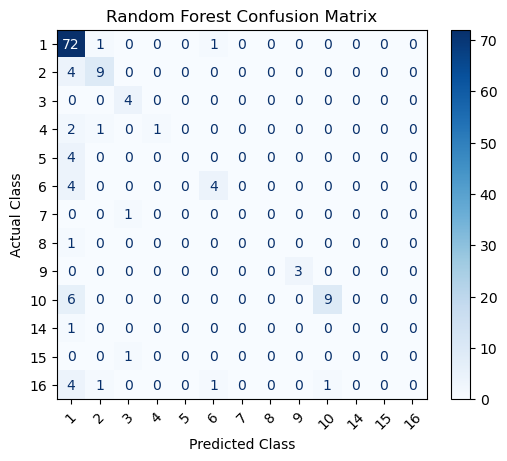

In [23]:
# Random Forest Confusion Matrix

class_labels = sorted(y_test.unique())

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=class_labels
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=class_labels
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)

plt.show()

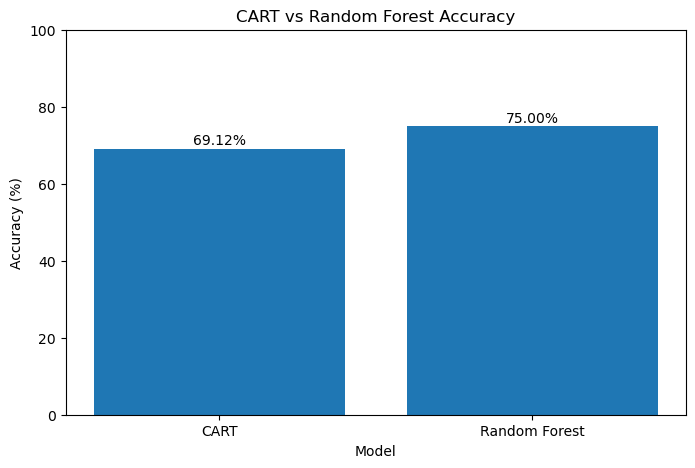

In [24]:
# Compare CART and Random Forest

models = ["CART", "Random Forest"]

accuracy_values = [
    cart_accuracy * 100,
    rf_accuracy * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracy_values)

plt.title("CART vs Random Forest Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

# Show values on top of bars
for bar, value in zip(bars, accuracy_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

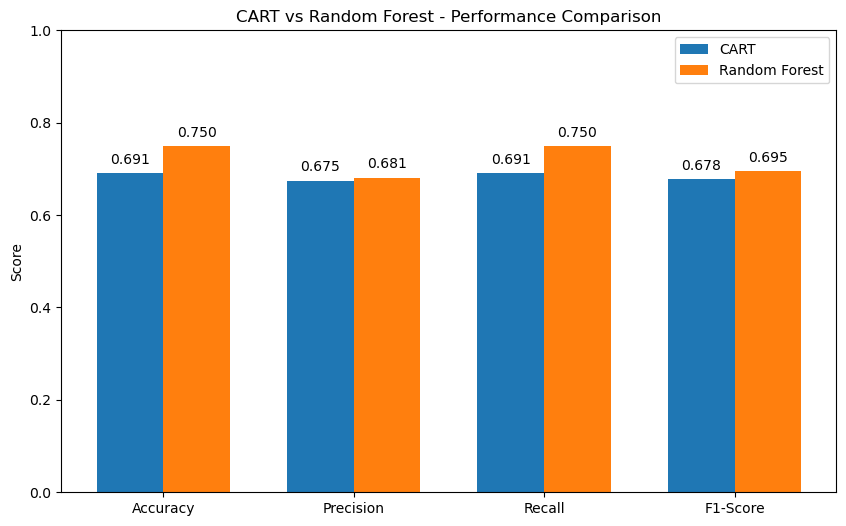

In [25]:
# Compare all evaluation metrics

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

cart_values = [
    cart_accuracy,
    cart_precision,
    cart_recall,
    cart_f1
]

rf_values = [
    rf_accuracy,
    rf_precision,
    rf_recall,
    rf_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(x - width/2, cart_values, width, label="CART")
bars2 = plt.bar(x + width/2, rf_values, width, label="Random Forest")

plt.title("CART vs Random Forest - Performance Comparison")
plt.ylabel("Score")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()

# Add values on top of bars
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.02,
            f"{value:.3f}",
            ha="center"
        )

plt.show()

In [26]:
# Final model comparison table

results = pd.DataFrame({
    "Model": ["CART", "Random Forest"],
    "Accuracy": [
        cart_accuracy,
        rf_accuracy
    ],
    "Precision": [
        cart_precision,
        rf_precision
    ],
    "Recall": [
        cart_recall,
        rf_recall
    ],
    "F1-Score": [
        cart_f1,
        rf_f1
    ]
})

# Display results
results

,Model,Accuracy,Precision,Recall,F1-Score
0,CART,0.691176,0.674585,0.691176,0.677985
1,Random Forest,0.750000,0.681010,0.750000,0.694742


In [28]:
# Create report-friendly results table

results_report = results.copy()

results_report["Accuracy"] = results_report["Accuracy"] * 100
results_report["Precision"] = results_report["Precision"] * 100
results_report["Recall"] = results_report["Recall"] * 100
results_report["F1-Score"] = results_report["F1-Score"] * 100

results_report = results_report.round(2)

print("Final Results:")
display(results_report)

Final Results:


,Model,Accuracy,Precision,Recall,F1-Score
0,CART,69.12,67.46,69.12,67.80
1,Random Forest,75.00,68.10,75.00,69.47


In [29]:
# Save final results

result_path = "../Result/model_comparison.csv"

results_report.to_csv(result_path, index=False)

print("Results saved successfully!")
print("Saved to:", result_path)

Results saved successfully!
Saved to: ../Result/model_comparison.csv


<Figure size 1000x800 with 0 Axes>

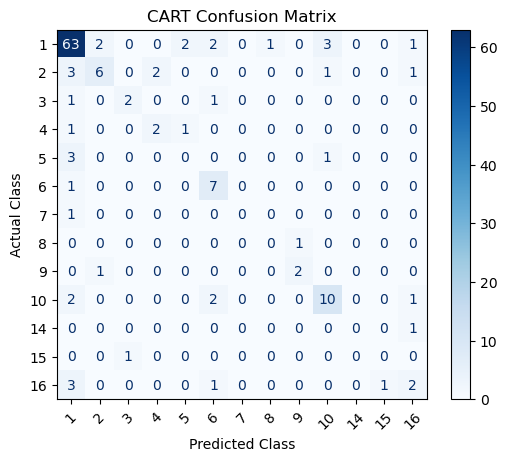

CART confusion matrix saved successfully!


In [30]:
# Save CART confusion matrix

class_labels = sorted(y_test.unique())

cm_cart = confusion_matrix(
    y_test,
    y_pred_cart,
    labels=class_labels
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cart,
    display_labels=class_labels
)

disp.plot(cmap="Blues", values_format="d")

plt.title("CART Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)

plt.savefig(
    "../Figure/cart_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("CART confusion matrix saved successfully!")

<Figure size 1000x800 with 0 Axes>

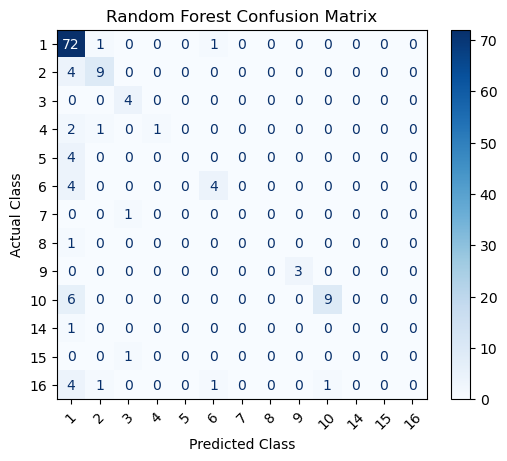

Random Forest confusion matrix saved successfully!


In [31]:
# Save Random Forest confusion matrix

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=class_labels
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=class_labels
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)

plt.savefig(
    "../Figure/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Random Forest confusion matrix saved successfully!")

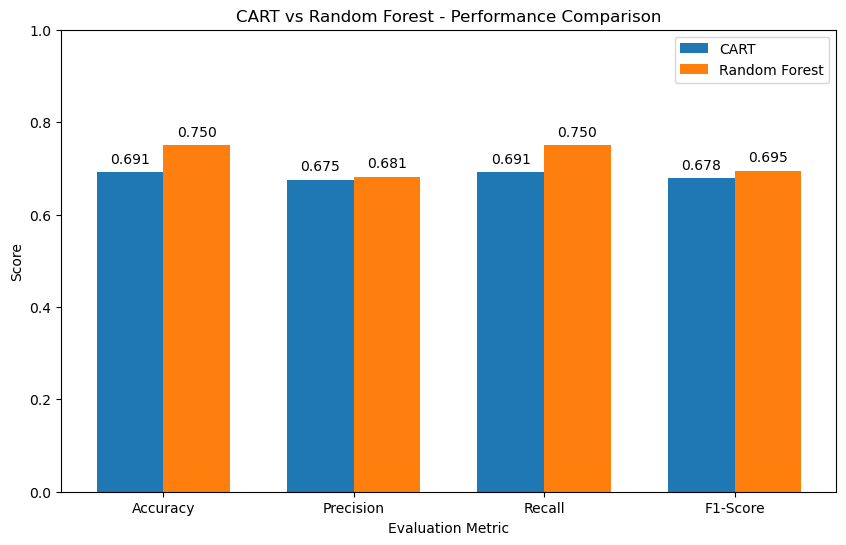

Performance comparison graph saved successfully!


In [32]:
# Save final performance comparison graph

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

cart_values = [
    cart_accuracy,
    cart_precision,
    cart_recall,
    cart_f1
]

rf_values = [
    rf_accuracy,
    rf_precision,
    rf_recall,
    rf_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width/2,
    cart_values,
    width,
    label="CART"
)

bars2 = plt.bar(
    x + width/2,
    rf_values,
    width,
    label="Random Forest"
)

plt.title("CART vs Random Forest - Performance Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()

# Add values on bars
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.02,
            f"{value:.3f}",
            ha="center"
        )

plt.savefig(
    "../Figure/performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance comparison graph saved successfully!")